# EdepPickUp: エネルギー損失の記録

Geant4 のステップのうち、TPC のガス・シンチ・アンチにエネルギーを落としたものをイベントごとに集め、
ツリー `edep` に書きます。後ろの検出器の応答のモジュールは、すべてこのモジュールから値を受け取ります。設定ファイルの `pickup` の節です。

| | |
| --- | --- |
| SMILE_tool_box | `SMILE_2p_Step`(`UserSteppingAction`)、`SMILE_2p::DepositInPSA`(HA_OFF の扱い)、sim.mac の `HA_OffFile` |
| ソース | `simulation_source/modules/EdepPickUp/` |
| 基底クラス | anlgeant4 の `VAppendableUserActionAssembly`(`StandardUserActionAssembly` の後ろにつなぐ) |

## 1. 何をするか

1. イベントの始め: 一次粒子(種類、エネルギー、位置、方向)を記録
2. ステップごと(`SteppingAction`): エネルギー損失が 0 より大きいステップを、立体の名前で振り分ける
   - `tpc_volume`(`TPC_detectable`): TPC のステップとして、エネルギー、位置、飛跡の番号、粒子、作った物理過程を記録
   - 名前に `scinti_keyword`(`scinti`)を含む: シンチのステップとして、立体の名前、コピー番号、エネルギー、位置を記録。
     `ha_off_file` に書かれた PMT(使っていない PMT)のステップは捨てる
   - `anti_volume`(`anti`): アンチのエネルギーの合計だけ
3. イベントの終わり: TPC かシンチにステップがあれば(`keep_empty_events = true` なら必ず)ツリーに書く

位置はステップの終点(`G4Track::GetPosition()`、SMILE_2p_Step と同じ)、単位は keV と mm です。

## 2. パラメータ

| パラメータ | 型 | 既定値(C++) | この設定の値 | 単位 | 説明 |
| --- | --- | --- | --- | --- | --- |
| `output` | string | edep.root | edep.root |  | エネルギー損失の TTree(edep)を書く ROOT ファイル |
| `ha_off_file` | string | (空) | {sim_data}/HA_OFF.dat |  | 使わない PMT の一覧(HA_OFF.dat)。そこのシンチのエネルギー損失は捨てる |
| `tpc_volume` | string | TPC_detectable | (設定に無い: 既定値) |  | TPC のガスの立体の名前 |
| `scinti_keyword` | string | scinti | (設定に無い: 既定値) |  | シンチの立体の名前に含まれる文字列 |
| `anti_volume` | string | anti | (設定に無い: 既定値) |  | アンチの立体の名前 |
| `keep_empty_events` | bool | false | (設定に無い: 既定値) |  | true: TPC にもシンチにもエネルギーを落としていないイベントも書く |

`run_sim.py -o <ファイル>` は `output` を上書きします。

パラメータは設定ファイル `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` の `pickup[0].parameters` に書きます
(書き方は `config/README.md`)。1 回だけ変えて試すときは `run_sim.py ... --set pickup.keep_empty_events=true` で上書きします。
「既定値(C++)」は設定ファイルに書かなかったときの値です。

## 3. ほかのモジュールとのやり取り

ほかのモジュールは `get_module("EdepPickUp", &edep_)` でこのモジュールを取り出し、次の関数で **今のイベント** の値を読みます(`EdepPickUp.hh`)。

| 関数 | 型 | 単位 | 中身 | 使うモジュール |
| --- | --- | --- | --- | --- |
| `EventID()` | int | | Geant4 のイベント番号 | TPCEmulator, HAEmulator, RawWriter2p |
| `PrimaryName()` | string | | 一次粒子の種類 | |
| `PrimaryEnergy()` | double | keV | 一次粒子の運動エネルギー | RawWriter2p |
| `PrimaryPos()`, `PrimaryDir()` | const double*(3 つ) | mm, なし | 一次粒子の位置、方向 | RawWriter2p |
| `TPCEnergy()`, `ScintiEnergy()`, `AntiEnergy()` | double | keV | TPC・シンチ・アンチのエネルギーの合計 | SimTrigger(アンチ)、RawWriter2p |
| `TPCStepE()`, `TPCStepX/Y/Z()` | vector<double> | keV, mm | TPC のステップごとのエネルギーと位置 | SimTrigger(数)、TPCEmulator |
| `ScintiStepVolume()`, `ScintiStepE()` | vector<string>, vector<double> | , keV | シンチのステップの立体の名前とエネルギー | SimTrigger(数)、HAEmulator |
| `ScintiStepX/Y/Z()` | vector<double> | mm | シンチのステップの位置 | |

ツリー `edep` の分岐は `../../DataIO_example.ipynb` の 4 節にあります(上の関数と同じ値)。

## 4. 確かめる

シンチの立体の名前 `scinti_<bottom|side>_<HA 番号>_<PMT 番号>_<ピクセル>` から、HA ごとのエネルギーを集めます。
`ha_off_file`(`HA_OFF.dat`)の 1 行は「HA の名前  PMT の ID + 1」です。立体の名前に入っているのは PMT の **名前** なので、
`HA_common` の対応(PMT の ID 0, 1, 2, 3, 4, 5 → 名前 6, 1, 3, 4, 5, 2)で直してから比べます。それらの PMT には何も記録されていないはずです。

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)
# 1_DataIO/DataIO_example.ipynb の出力(d10 の熱中性子、100 万個、seed 1)を使う
SIM = REPO / "tutorials_simulation" / "cache" / "d10_seed1_1M"
EDEP, RAW = SIM / "edep.root", SIM / "raw"
assert EDEP.exists(), "先に ../../DataIO_example.ipynb を実行してください"

def flat(column):
    # RDataFrame.AsNumpy() の vector 型の列 -> 全イベントをつないだ 1 次元の numpy 配列
    return np.concatenate([np.asarray(v) for v in column]) if len(column) else np.array([])

例: ['scinti_bottom_2_2_14' 'scinti_bottom_2_2_14' 'scinti_bottom_2_2_14']
使っていない (HA, PMT の名前): [(7, 6), (7, 1), (7, 3), (7, 4), (7, 5), (7, 2), (27, 5), (27, 1)]
その PMT のステップ: 0


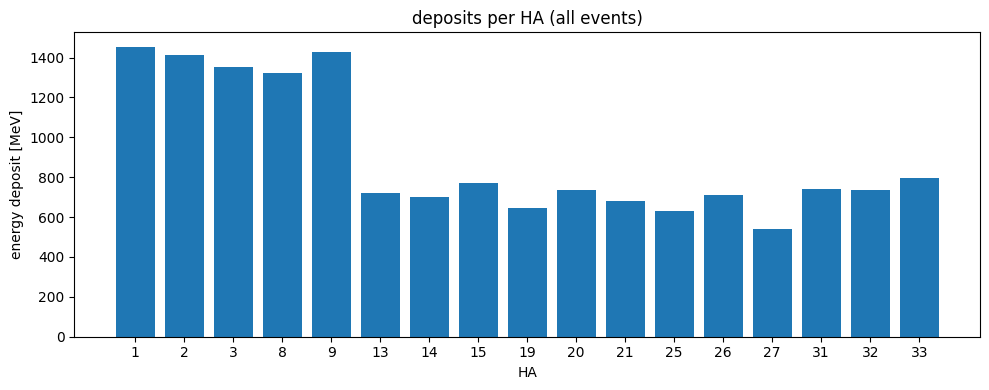

In [2]:
d = ROOT.RDataFrame("edep", str(EDEP)).AsNumpy(["sci_volume", "sci_e"])
vol = np.concatenate([np.array([str(s) for s in v]) for v in d["sci_volume"]]); e = flat(d["sci_e"])
parts = np.array([v.split("_") for v in vol])
ha, pmt = parts[:, 2].astype(int), parts[:, 3].astype(int)
print("例:", vol[:3])
PMT_ID_TO_NAME = {0: 6, 1: 1, 2: 3, 3: 4, 4: 5, 5: 2}      # HA_common の pmt_map
off = np.loadtxt(cfg["pickup"][0]["parameters"]["ha_off_file"], dtype=int, ndmin=2)
off = [(int(a), PMT_ID_TO_NAME[int(p) - 1]) for a, p in off]
print("使っていない (HA, PMT の名前):", off)
print("その PMT のステップ:", sum(((ha == a) & (pmt == p)).sum() for a, p in off))

has = np.unique(ha)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([str(x) for x in has], [e[ha == x].sum() / 1e3 for x in has])
ax.set_xlabel("HA"); ax.set_ylabel("energy deposit [MeV]"); ax.set_title("deposits per HA (all events)")
fig.tight_layout(); plt.show()